<a href="https://colab.research.google.com/github/anupbagale/neural-networks-from-scratch/blob/main/notebooks/08_fuzzy_sets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 8: Fuzzy Sets

Lesson 8 of 8, about 30 minutes.

After this lesson you should be able to:

1. Represent vague concepts as fuzzy sets with membership values between 0 and 1.
2. Compute the complement, union, intersection and difference of fuzzy sets.
3. Check which laws of ordinary set algebra still hold for fuzzy sets, and which do not.
4. Relate fuzzy membership to the graded outputs of sigmoid neurons.

You will need: basic set theory (union, intersection, complement).

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/neural-networks-from-scratch"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Crisp and fuzzy sets

An ordinary (crisp) set has a sharp edge: 24 °C is either "warm" or it is not. Zadeh (1965)
suggested letting each element belong to a set to some degree, given by a membership value
$\mu_A(x) \in [0, 1]$. Fuzzy sets are the basis of fuzzy logic and fuzzy control. The idea of a
graded answer is also close to the sigmoid neurons of lesson 2, whose outputs are not just 0 or 1.

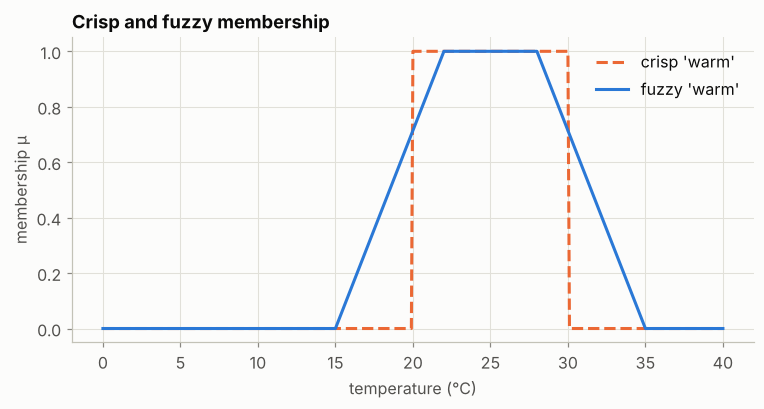

In [2]:
temps = np.linspace(0, 40, 401)
crisp_warm = ((temps >= 20) & (temps <= 30)).astype(float)
fuzzy_warm = np.clip(np.minimum((temps - 15) / 7, (35 - temps) / 7), 0, 1)   # trapezoid 15, 22, 28, 35

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(temps, crisp_warm, color=PALETTE[1], ls="--", label="crisp 'warm'")
ax.plot(temps, fuzzy_warm, color=PALETTE[0], label="fuzzy 'warm'")
ax.set(xlabel="temperature (°C)", ylabel="membership μ", title="Crisp and fuzzy membership")
ax.legend()
plt.show()

## Operations

| operation | definition |
|---|---|
| complement | $\mu_{\bar A}(x) = 1 - \mu_A(x)$ |
| union | $\mu_{A \cup B}(x) = \max\big(\mu_A(x), \mu_B(x)\big)$ |
| intersection | $\mu_{A \cap B}(x) = \min\big(\mu_A(x), \mu_B(x)\big)$ |
| difference | $\mu_{A - B}(x) = \min\big(\mu_A(x), 1 - \mu_B(x)\big)$ |

We use the two sets from the original lab on the universe $X = \{1, 2, 3, 4, 5\}$.
`nnlab.fuzzy.FuzzySet` supports `~`, `|`, `&` and `-` for these four operations.

In [3]:
from nnlab.fuzzy import FuzzySet, check_properties

X = [1, 2, 3, 4, 5]
A = FuzzySet(X, [0, 1, 0.5, 0.3, 0.2], name="A")
B = FuzzySet(X, [0, 0.5, 0.7, 0.2, 0.4], name="B")

for s in [A, B, ~A, ~B, A | B, A & B, A - B, B - A]:
    print(s)

A = {0/1, 1/2, 0.5/3, 0.3/4, 0.2/5}
B = {0/1, 0.5/2, 0.7/3, 0.2/4, 0.4/5}
¬A = {1/1, 0/2, 0.5/3, 0.7/4, 0.8/5}
¬B = {1/1, 0.5/2, 0.3/3, 0.8/4, 0.6/5}
(A ∪ B) = {0/1, 1/2, 0.7/3, 0.3/4, 0.4/5}
(A ∩ B) = {0/1, 0.5/2, 0.5/3, 0.2/4, 0.2/5}
(A − B) = {0/1, 0.5/2, 0.3/3, 0.3/4, 0.2/5}
(B − A) = {0/1, 0/2, 0.5/3, 0.2/4, 0.4/5}


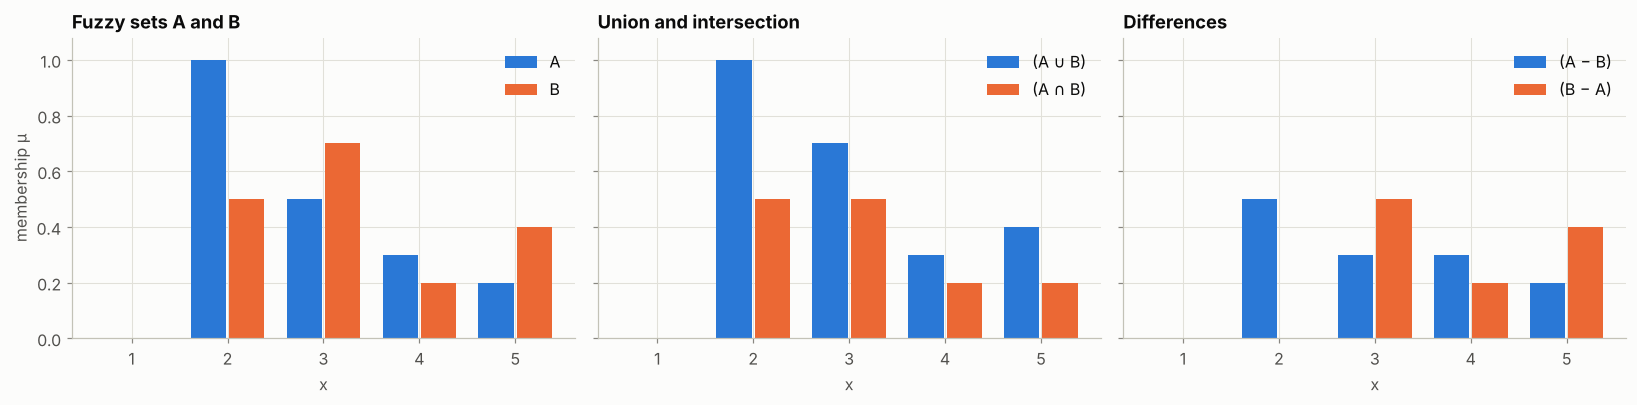

In [4]:
def bars(ax, sets, title):
    width = 0.8 / len(sets)
    for i, (s, color) in enumerate(zip(sets, PALETTE)):
        ax.bar(np.array(X) + (i - (len(sets) - 1) / 2) * width, s.membership, width=width * 0.92,
               color=color, label=s.name)
    ax.set(xticks=X, ylim=(0, 1.08), title=title, xlabel="x")
    ax.legend(loc="upper right")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
bars(axes[0], [A, B], "Fuzzy sets A and B")
bars(axes[1], [A | B, A & B], "Union and intersection")
bars(axes[2], [A - B, B - A], "Differences")
axes[0].set_ylabel("membership μ")
fig.tight_layout()
plt.show()

A note on the first version of this notebook: a few labels were swapped there. The check printed as
"associative" was really testing commutativity, and the other way round. $\min(\mu_B, 1 - \mu_A)$
was labelled $A - V$, although it is $B - A$ (the second set was called $V$). The De Morgan check
printed $\bar A \cap \bar B$ under the name "(A ∩ V) complement". The names below are corrected.

## Which set laws still hold?

In [5]:
C = FuzzySet(X, [0.4, 0.2, 0.7, 1, 0.5], name="C")
for law, holds in check_properties(A, B, C).items():
    print(f"{'holds' if holds else 'FAILS'}  {law}")

holds  commutative (∪)
holds  commutative (∩)
holds  associative (∪)
holds  associative (∩)
holds  distributive (∪ over ∩)
holds  distributive (∩ over ∪)
holds  De Morgan ¬(A ∪ B) = ¬A ∩ ¬B
holds  De Morgan ¬(A ∩ B) = ¬A ∪ ¬B
holds  involution ¬¬A = A
FAILS  excluded middle A ∪ ¬A = X
FAILS  non-contradiction A ∩ ¬A = ∅


Commutativity, associativity, distributivity, double complement and both De Morgan laws work the
same way as for crisp sets. Two laws do not:

- The law of the excluded middle, $A \cup \bar A = X$, fails: $\mu_{A \cup \bar A}(3) = \max(0.5, 0.5) = 0.5$, not 1.
- The law of non-contradiction, $A \cap \bar A = \varnothing$, fails: $\mu_{A \cap \bar A}(3) = 0.5$, not 0.

This is what fuzzy sets are meant to allow. A temperature can be partly warm and partly not warm
at the same time.

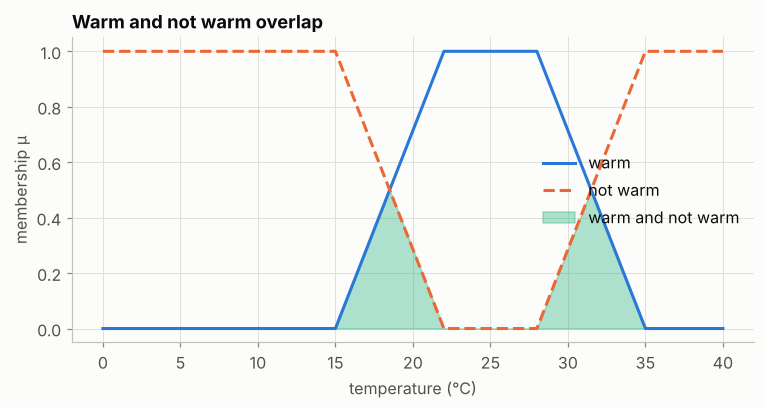

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
not_warm = 1 - fuzzy_warm
ax.plot(temps, fuzzy_warm, color=PALETTE[0], label="warm")
ax.plot(temps, not_warm, color=PALETTE[1], ls="--", label="not warm")
ax.fill_between(temps, np.minimum(fuzzy_warm, not_warm), color=PALETTE[2], alpha=0.35,
                label="warm and not warm")
ax.set(xlabel="temperature (°C)", ylabel="membership μ", title="Warm and not warm overlap")
ax.legend(loc="center right")
plt.show()

## Exercises

1. Write membership functions for "cold" and "hot" on the temperature axis. Plot "warm or hot" and
   "not cold and not hot".
2. Max and min are not the only possible operators. The algebraic versions use
   $\mu_{A\cap B} = \mu_A \mu_B$ and $\mu_{A\cup B} = \mu_A + \mu_B - \mu_A\mu_B$. Which of the laws
   above still hold with these?

**Answer to exercise 2**

<details><summary>Answer</summary>

Commutativity, associativity and De Morgan's laws still hold. Idempotence ($A \cap A = A$) and distributivity fail. You can check this by writing two small functions and comparing the results with `np.allclose`.

</details>

## Summary

- A fuzzy set gives each element a membership value between 0 and 1.
- Complement, union, intersection and difference are 1 − μ, max, min and min(μ_A, 1 − μ_B).
- Most set laws still hold, but the excluded middle and non-contradiction do not.
- Graded membership is similar to the graded output of a sigmoid neuron.

This is the last lesson. The [README](../README.md) lists all eight.

### References

- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353.
- Klir, G. J., & Yuan, B. (1995). *Fuzzy Sets and Fuzzy Logic: Theory and Applications*. Prentice Hall.